Part 2: Logistic Regression

Student Dropout and Academic Success: Supervised Classification (3 classes)

Algorithm: Logistic Regression (multi-class). It learns a weight for each feature and turns the weighted sum into a probability for each of the 3 classes.

Problem to solve: the "Enrolled" class is small (about 18%), so a normal model rarely predicts it. We compare three versions of Logistic Regression:

Baseline: no special handling

Class-weighted: mistakes on small classes are penalised more

SMOTE: create extra synthetic "Enrolled" examples in the training data

1. Import libraries and load the prepared data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE    # creates synthetic samples of the small class

RANDOM_STATE = 42

In [2]:
# Load the train/test data prepared in notebook 01
X_train = pd.read_csv("../data/X_train.csv")
X_test = pd.read_csv("../data/X_test.csv")
y_train = pd.read_csv("../data/y_train.csv")["Target"]
y_test = pd.read_csv("../data/y_test.csv")["Target"]
le = joblib.load("../data/label_encoder.pkl")

class_names = list(le.classes_)    # ['Dropout', 'Enrolled', 'Graduate']
print("Training:", X_train.shape, "| Test:", X_test.shape)
print("Classes:", class_names)


Training: (3539, 238) | Test: (885, 238)
Classes: ['Dropout', 'Enrolled', 'Graduate']


2. A helper function to score each model

Accuracy = share of all predictions that are correct.

Macro F1 = average F1 score of the three classes (treats every class equally, so it is fairer when classes are imbalanced).
 
Recall = of the students who truly belong to a class, how many did the model find? We look at it per class, especially Enrolled.

In [3]:
def score_model(name, y_true, y_pred):
    """Return the important scores of one model as a dictionary."""
    recalls = recall_score(y_true, y_pred, average=None)   # one recall value per class
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Recall (Dropout)": recalls[0],
        "Recall (Enrolled)": recalls[1],
        "Recall (Graduate)": recalls[2],
    }

all_results = []   # we will add each model's scores to this list

3. Model A: Baseline Logistic Regression

In [4]:
# Train with default settings (no imbalance handling)
lr_baseline = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
lr_baseline.fit(X_train, y_train)

# Predict on the test set and store the scores
pred_baseline = lr_baseline.predict(X_test)
all_results.append(score_model("LR - Baseline", y_test, pred_baseline))

print(classification_report(y_test, pred_baseline, target_names=class_names))

              precision    recall  f1-score   support

     Dropout       0.79      0.76      0.78       284
    Enrolled       0.55      0.37      0.44       159
    Graduate       0.81      0.92      0.86       442

    accuracy                           0.77       885
   macro avg       0.72      0.69      0.69       885
weighted avg       0.76      0.77      0.76       885



Key insight: 

Enrolled row: its recall is low, so the model misses many Enrolled students.

4. Model B: Class-weighted Logistic Regression

In [5]:
# class_weight="balanced" makes mistakes on the small class count more during training
lr_weighted = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
lr_weighted.fit(X_train, y_train)

pred_weighted = lr_weighted.predict(X_test)
all_results.append(score_model("LR - Class-weighted", y_test, pred_weighted))

print(classification_report(y_test, pred_weighted, target_names=class_names))

              precision    recall  f1-score   support

     Dropout       0.81      0.70      0.75       284
    Enrolled       0.42      0.62      0.50       159
    Graduate       0.86      0.79      0.82       442

    accuracy                           0.73       885
   macro avg       0.70      0.70      0.69       885
weighted avg       0.77      0.73      0.74       885



5. Model C: Logistic Regression with SMOTE

SMOTE creates new, synthetic "Enrolled" and "Dropout" rows until all classes are the same size.
SMOTE is applied to the training data only. The test data stays untouched, because it must represent real students.

In [6]:
# Balance the training data
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Class counts before SMOTE:", np.bincount(y_train))
print("Class counts after SMOTE :", np.bincount(y_train_smote))

Class counts before SMOTE: [1137  635 1767]
Class counts after SMOTE : [1767 1767 1767]


In [7]:
# Train on the balanced data, evaluate on the original (untouched) test data
lr_smote = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
lr_smote.fit(X_train_smote, y_train_smote)

pred_smote = lr_smote.predict(X_test)
all_results.append(score_model("LR - SMOTE", y_test, pred_smote))

print(classification_report(y_test, pred_smote, target_names=class_names))

              precision    recall  f1-score   support

     Dropout       0.81      0.71      0.76       284
    Enrolled       0.41      0.60      0.49       159
    Graduate       0.86      0.79      0.82       442

    accuracy                           0.73       885
   macro avg       0.69      0.70      0.69       885
weighted avg       0.76      0.73      0.74       885



6. Compare the three versions

In [8]:
results_df = pd.DataFrame(all_results).set_index("Model").round(4)
results_df

,Accuracy,Macro F1,Recall (Dropout),Recall (Enrolled),Recall (Graduate)
Model,,,,,
LR - Baseline,0.7718,0.6938,0.7641,0.3711,0.9208
LR - Class-weighted,0.7288,0.6904,0.7007,0.6164,0.7873
LR - SMOTE,0.7288,0.6893,0.7148,0.5975,0.7851


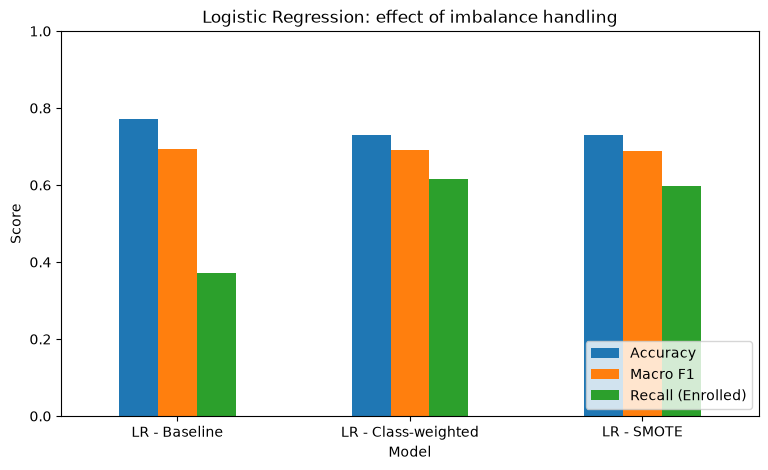

In [9]:
# Chart: compare the three versions on three key scores
results_df[["Accuracy", "Macro F1", "Recall (Enrolled)"]].plot(kind="bar", figsize=(9, 5))
plt.title("Logistic Regression: effect of imbalance handling")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

7. Confusion matrices

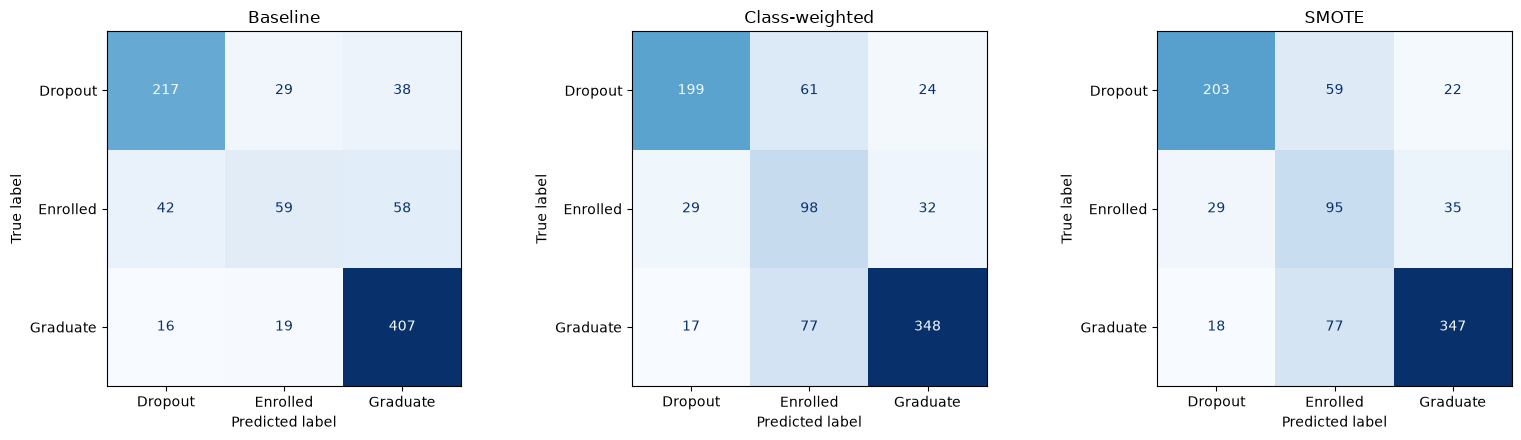

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name, pred in zip(axes,
                          ["Baseline", "Class-weighted", "SMOTE"],
                          [pred_baseline, pred_weighted, pred_smote]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=class_names).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

8. Save results for the final comparison

In [11]:
results_df.reset_index().to_csv("../results/logreg_results.csv", index=False)
print("Saved to ../results/logreg_results.csv")

Saved to ../results/logreg_results.csv


9. Conclusion (Logistic Regression)

Results on the test set (885 students):

Model	        Accuracy	Macro F1	Recall (Enrolled)
LR - Baseline	0.772	     0.694	      0.371
LR - Class-weighted	0.729	 0.690	      0.616
LR - SMOTE	    0.729	     0.690	      0.598

The baseline looks best on accuracy (77%), but it finds only 37% of the Enrolled students. Accuracy hides this problem because Enrolled is the smallest class.

Class-weighting and SMOTE raise Enrolled recall a lot (to about 60%), so far more Enrolled students are identified.
There is a trade-off. Accuracy drops by about 4 points because the model now makes more mistakes on the Graduate and Dropout classes. Macro F1 stays roughly the same.

Insights:

Which version is best depends on the goal - If the university wants to find as many at-risk or undecided students as possible, class-weighted or SMOTE is the better choice. If only overall accuracy matters, the baseline wins.

